# **MODELO DE CLUSTERING**

*Se tiene un dataset dentro de una tabla llamada Aula.csv, que contiene mediciones de tres puntos en tres aulas. El presente modelo de clustering realiza un análisis categórico comparativo mediante los algoritmos K-Means y Fuzzy C-Means, con el objetivo de agrupar los datos y determinar a qué aula pertenecen las mediciones.*

Importar Librerías

In [82]:
!pip install scikit-fuzzy
import pandas as pd  # Para manipulación de tablas y lectura del CSV
import numpy as np # Para operaciones numéricas y manejo de matrices
import matplotlib.pyplot as plt  # Para la creación de gráficos y visualizaciones
import skfuzzy as fuzz # Para Fuzzy C-Means
from mpl_toolkits.mplot3d import Axes3D  # Extensión para proyecciones en tres dimensiones
from sklearn.preprocessing import StandardScaler # Para estandarizar/normalizar los datos
from sklearn.cluster import KMeans # Para K-Means
from sklearn.metrics import silhouette_score # Métrica para evaluar la calidad del agrupamiento

Montar Drive

In [83]:
from google.colab import drive
# Montar Google Drive (solicitará permisos de acceso)
drive.mount('/content/drive')

# Cargar el dataset desde la ruta proporcionada
df = pd.read_csv('/content/drive/MyDrive/Aulas.csv')

# Mostrar información general del dataset (columnas, tipos de datos, etc.)
print("--- Información del Dataset ---")
df.info()
print("\n")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
--- Información del Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   T1      300 non-null    float64
 1   T2      300 non-null    float64
 2   T3      300 non-null    float64
 3   Aula    300 non-null    int64  
dtypes: float64(3), int64(1)
memory usage: 9.5 KB




Visualización 3D de los Datos Originales

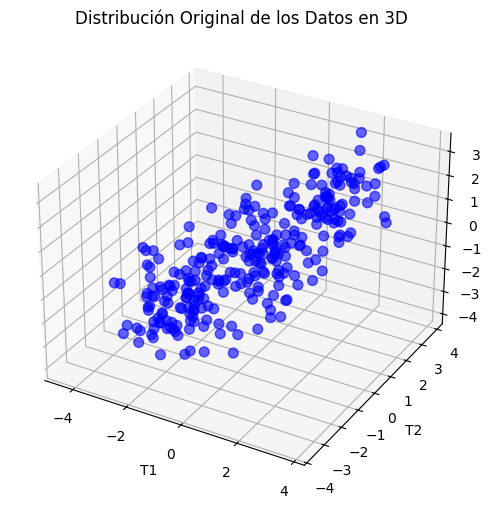

In [84]:
# Extraer solo las características de medición
X = df[['T1', 'T2', 'T3']]

# Configurar la figura para la gráfica 3D
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

# Crear el gráfico de dispersión con un solo color para todos los puntos
ax.scatter(X['T1'], X['T2'], X['T3'], c='blue', marker='o', s=50, alpha=0.6)

# Etiquetas y título
ax.set_xlabel('T1')
ax.set_ylabel('T2')
ax.set_zlabel('T3')
ax.set_title('Distribución Original de los Datos en 3D')

plt.show()


Normalización de los datos

In [86]:
scaler = StandardScaler()

# Aplicamos la normalización a las columnas T1, T2 y T3
X_scaled = scaler.fit_transform(X)

# Convertimos de vuelta a un DataFrame para facilitar su manejo
X_scaled_df = pd.DataFrame(X_scaled, columns=['T1', 'T2', 'T3'])

print("\n--- Datos Normalizados ---")
print(X_scaled_df.head())


--- Datos Normalizados ---
         T1        T2        T3
0 -1.282281 -1.402518 -0.624565
1 -1.684315 -1.095471 -0.977094
2 -0.934707 -1.329806 -0.393191
3 -0.465150 -0.962190 -1.440945
4 -1.191237 -0.371069 -0.775170


Modelo K-Means y Etiquetado

In [87]:
# Establecer la cantidad de agrupaciones a buscar (las 3 aulas)
k_aulas = 3

# Creación y entrenamiento del modelo
modelo_km = KMeans(n_clusters=k_aulas, random_state=42, n_init=10)
modelo_km.fit(X_scaled_df)

# Extraer las predicciones del modelo
etiquetas_km = modelo_km.labels_

# Agregar las nuevas columnas a nuestros dataframes
df['Grupo_KMeans'] = etiquetas_km
X_scaled_df['Grupo_KMeans'] = etiquetas_km

# Mostrar el resultado USANDO LA TABLA NORMALIZADA
print("--- Resultados con K-Means (Datos Normalizados) ---")
display(X_scaled_df.head())

--- Resultados con K-Means (Datos Normalizados) ---


,T1,T2,T3,Grupo_KMeans
0,-1.282281,-1.402518,-0.624565,2
1,-1.684315,-1.095471,-0.977094,2
2,-0.934707,-1.329806,-0.393191,2
3,-0.465150,-0.962190,-1.440945,2
4,-1.191237,-0.371069,-0.775170,2


Visualización en 3D de K-Means

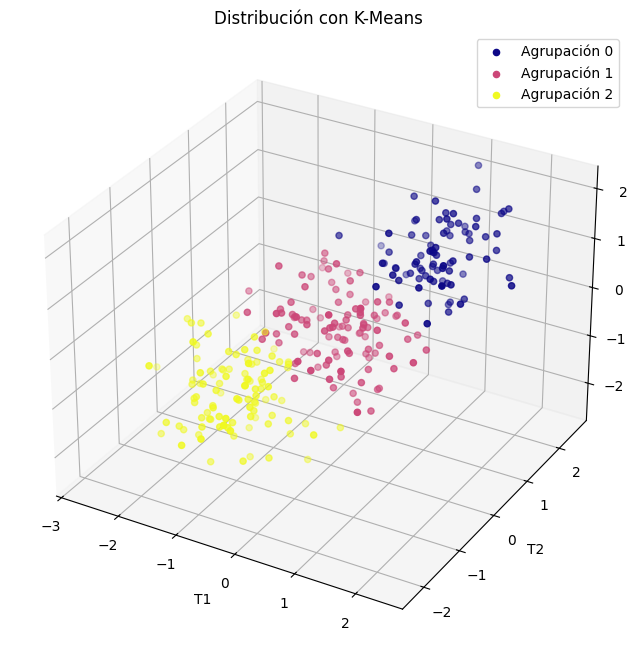

In [89]:
# Creación de la figura
figura_km = plt.figure(figsize=(10, 8))
eje_km = figura_km.add_subplot(111, projection='3d')

# Selección de paleta de colores
colores = plt.get_cmap('plasma', k_aulas)

# Iteración para graficar cada agrupación (USANDO X_scaled_df)
for i in range(k_aulas):
    filtro_grupo = X_scaled_df[X_scaled_df['Grupo_KMeans'] == i]

    eje_km.scatter(filtro_grupo['T1'], filtro_grupo['T2'], filtro_grupo['T3'],
                   color=colores(i), label=f'Agrupación {i}', marker='o')

# Configuraciones de etiquetas (Aclaramos que son estandarizadas)
eje_km.set_xlabel('T1')
eje_km.set_ylabel('T2')
eje_km.set_zlabel('T3')
eje_km.set_title('Distribución con K-Means')
eje_km.legend()

plt.show()

Modelo de Fuzzy C-Means y etiquetado

In [90]:
# Preparar la matriz para skfuzzy (asegurando no usar la columna extra de KMeans)
columnas_medicion = ['T1', 'T2', 'T3']
matriz_difusa = X_scaled_df[columnas_medicion].values.T

# Entrenamiento del modelo difuso
centroides, membresia, u0, d, jm, p, fpc = fuzz.cluster.cmeans(
    matriz_difusa, c=k_aulas, m=2, error=0.005, maxiter=100, init=None, seed=42
)

# Determinar la clase final según la probabilidad más alta
predicciones_fcm = np.argmax(membresia, axis=0)

# Guardar los resultados
df['Grupo_Fuzzy'] = predicciones_fcm
X_scaled_df['Grupo_Fuzzy'] = predicciones_fcm

# Verificar la adición de la columna del grupo Fuzzy USANDO LA TABLA NORMALIZADA
print("--- Resultados con Fuzzy C-Means ---")
display(X_scaled_df.head())

--- Resultados con Fuzzy C-Means ---


,T1,T2,T3,Grupo_KMeans,Grupo_Fuzzy
0,-1.282281,-1.402518,-0.624565,2,1
1,-1.684315,-1.095471,-0.977094,2,1
2,-0.934707,-1.329806,-0.393191,2,1
3,-0.465150,-0.962190,-1.440945,2,1
4,-1.191237,-0.371069,-0.775170,2,1


Visualización en 3D de Fuzzy C-Means

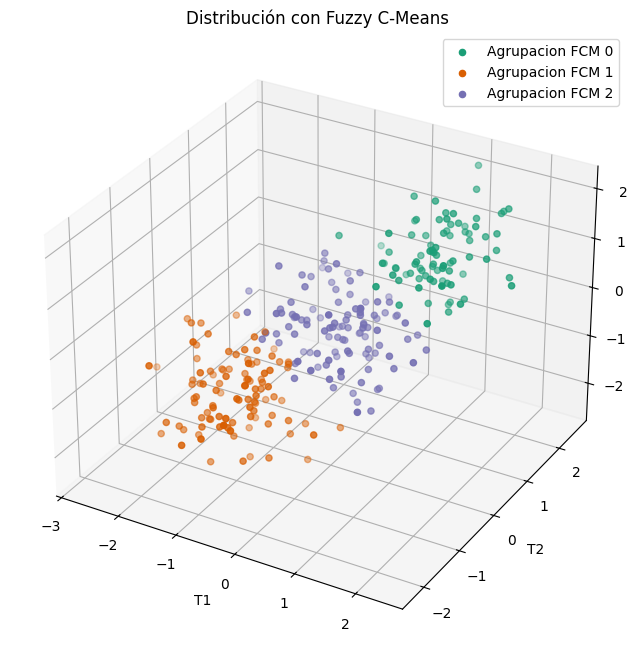

In [91]:
# Creación de la figura
figura_fcm = plt.figure(figsize=(10, 8))
eje_fcm = figura_fcm.add_subplot(111, projection='3d')

# Selección de paleta de colores
colores_difusos = plt.get_cmap('Dark2')

# Iteración para graficar cada clase difusa (USANDO X_scaled_df)
for i in range(k_aulas):
    filtro_fcm = X_scaled_df[X_scaled_df['Grupo_Fuzzy'] == i]

    eje_fcm.scatter(filtro_fcm['T1'], filtro_fcm['T2'], filtro_fcm['T3'],
                    color=colores_difusos(i), label=f'Agrupacion FCM {i}', marker='o')

# Configuraciones de etiquetas
eje_fcm.set_xlabel('T1')
eje_fcm.set_ylabel('T2')
eje_fcm.set_zlabel('T3')
eje_fcm.set_title('Distribución con Fuzzy C-Means')
eje_fcm.legend()

plt.show()

Análisis de resultados basados en la silueta de cada modelo

In [92]:
# Aislamos las mediciones para que el cálculo sea exacto
datos_limpios = X_scaled_df[['T1', 'T2', 'T3']]

# Cálculo de las métricas de silueta
silueta_km = silhouette_score(datos_limpios, df['Grupo_KMeans'])
silueta_difusa = silhouette_score(datos_limpios, df['Grupo_Fuzzy'])
silueta_original = silhouette_score(datos_limpios, df['Aula'])

# Impresión de resultados
print("========== RESULTADOS DE SILUETA ==========")
print(f"Información Original (Referencia): {silueta_original:.8f}")
print(f"KMeans Coeficiente de Silueta promedio: {silueta_km:.8f}")
print(f"Fuzzy C-Means Coeficiente de Silueta promedio: {silueta_difusa:.8f}")
print("===========================================\n")

# Lógica de evaluación de semejanza (Comparación con la realidad)
brecha_km = abs(silueta_original - silueta_km)
brecha_fcm = abs(silueta_original - silueta_difusa)

if brecha_km < brecha_fcm:
    print(">> CONCLUSIÓN: El algoritmo K-Means es el que más se asemeja a la estructura de la información original.")
elif brecha_fcm < brecha_km:
    print(">> CONCLUSIÓN: El algoritmo Fuzzy C-Means es el que más se asemeja a la estructura de la información original.")
else:
    print(">> CONCLUSIÓN: Ambos algoritmos replicaron la estructura original con el mismo nivel de semejanza.")

========== RESULTADOS DE SILUETA ==========
Información Original (Referencia): 0.34694750
KMeans Coeficiente de Silueta promedio: 0.38967185
Fuzzy C-Means Coeficiente de Silueta promedio: 0.38967185

>> CONCLUSIÓN: Ambos algoritmos replicaron la estructura original con el mismo nivel de semejanza.
